In [74]:
# GEREKLİ KÜTÜPHANELERİN EKLENMESİ

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [73]:
df = pd.read_csv('ogrenci_veriler.csv') # dosyayı okuduk

print("Veri Boyutu (Satır, Sütun):", df.shape) # tablonun satır ve sütun sayısını aldık
print(df.head()) # veri setinin ilk 5 verisini ekrana yazdırdık

print("\nİstatistikler:\n", df.describe()) # sayısal sütunların temel istatiklerini çıkardık

print("\nEksik Değerler:\n", df.isnull().sum()) # boş olan(null) değerleri topladık
df = df.dropna()  # Eksik satırları temizledik

# calisma_saati, uyku_suresi  sütunları özellik sütunudur
# sinav_puani  sütunu hedef sütunudur

Veri Boyutu (Satır, Sütun): (30, 4)
   calisma_saati  uyku_suresi  sinav_puani  gecme_durumu
0            3.7          7.6         62.0             1
1            5.5          6.0         74.5             1
2            7.1          8.4         91.0             1
3            2.6          3.0         35.0             0
4            2.1          8.9         45.0             0

İstatistikler:
        calisma_saati  uyku_suresi  sinav_puani  gecme_durumu
count      30.000000    30.000000    30.000000     30.000000
mean        4.476667     6.603333    60.650000      0.700000
std         1.962877     1.880661    19.976344      0.466092
min         1.200000     2.000000    20.000000      0.000000
25%         2.950000     6.025000    46.000000      0.000000
50%         4.350000     7.050000    64.500000      1.000000
75%         6.025000     7.975000    75.625000      1.000000
max         7.900000     8.900000    91.000000      1.000000

Eksik Değerler:
 calisma_saati    0
uyku_suresi      0


In [76]:
# Geçme durumunun yüzdesel oranlarını hesaplayıp ekrana yazdırdık
print("\nGeçme Durumu Dağılımı:\n", df["gecme_durumu"].value_counts(normalize=True))

# Geçme durumlarına göre ortalama çalışma saatlerini karşılaştırmak için hazırlık yaptık
print("\nÇalışma Saati Ortalaması (Geçme Durumuna Göre):\n")
print(df.groupby("gecme_durumu")["calisma_saati"].mean())


Geçme Durumu Dağılımı:
 gecme_durumu
1    0.7
0    0.3
Name: proportion, dtype: float64

Çalışma Saati Ortalaması (Geçme Durumuna Göre):

gecme_durumu
0    2.288889
1    5.414286
Name: calisma_saati, dtype: float64


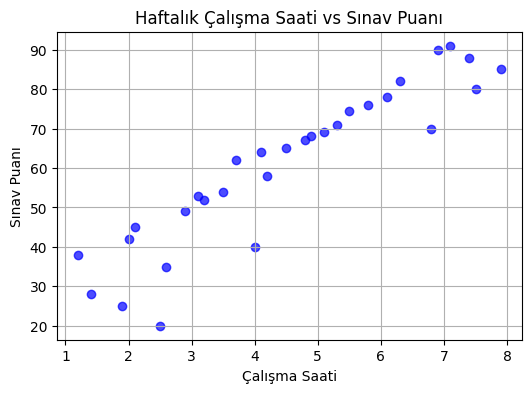

In [77]:
# Grafik 1: Çalışma Saati ile Sınav Puanı Dağılımı (Scatter Plot)

plt.figure(figsize=(6, 4))
plt.scatter(
    df["calisma_saati"], df["sinav_puani"], color="blue", alpha=0.7
)  # çalışma saati ve sınav puanı arasındaki ilişkiyi noktalarla gösterdik
plt.title("Haftalık Çalışma Saati vs Sınav Puanı")  # grafiğe başlık verdik
plt.xlabel("Çalışma Saati")  # x eksenini etiketledik
plt.ylabel("Sınav Puanı")  # y eksenini etiketledik
plt.grid(True)  # grafiğe kılavuz çizgileri ekledik
plt.show()

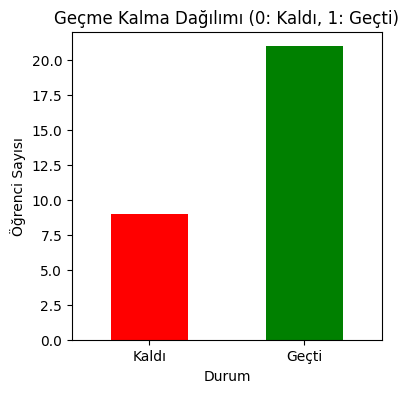

In [78]:
# Grafik 2: Geçen ve Kalan Öğrenci Sayısı (Bar Chart)

plt.figure(figsize=(4, 4))
df["gecme_durumu"].value_counts().sort_index().plot(
    kind="bar", color=["red", "green"]
)  # kalanları kırmızı, geçenleri yeşil sütunlar olarak çizdik
plt.title("Geçme Kalma Dağılımı (0: Kaldı, 1: Geçti)")  # başlık ekledik
plt.xlabel("Durum")  # x eksenini etiketledik
plt.ylabel("Öğrenci Sayısı")  # y eksenini etiketledik
plt.xticks(
    ticks=[0, 1], labels=["Kaldı", "Geçti"], rotation=0
)  # sayıları anlaşılır isimlerle değiştirdik
plt.show()

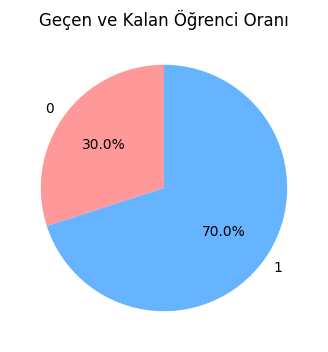

In [79]:
# Grafik 3: Geçen ve Kalan Öğrenci Oranı (Pie Chart - Pasta Grafiği)

plt.figure(figsize=(4, 4))
df["gecme_durumu"].value_counts().sort_index().plot(
    kind="pie",
    colors=["#ff9999", "#66b3ff"],
    autopct="%1.1f%%",
    startangle=90,
)  # öğrencilerin geçme/kalma yüzdelerini pasta grafiği ile gösterdik
plt.title("Geçen ve Kalan Öğrenci Oranı")  # başlık ekledik
plt.ylabel("")  # gereksiz y ekseni etiketini kaldırdık
plt.show()

In [80]:
# MODEL KURMA VE EĞİTME

X = df[["calisma_saati", "uyku_suresi"]] # özellik sütunları
y = df["sinav_puani"] # hedef sütunu

# Eğitim ve Test Olarak Bölme (%80 Eğitim, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Eğitim seti boyutu (X_train):", X_train.shape)
print("Test seti boyutu (X_test):", X_test.shape)

# Model Seçimi ve Eğitme
model = LinearRegression()
model.fit(X_train, y_train)

print("Model başarıyla eğitildi!")

Eğitim seti boyutu (X_train): (24, 2)
Test seti boyutu (X_test): (6, 2)
Model başarıyla eğitildi!


In [81]:
# TAHMİN VE DEĞERLENDİRME

# Test verileri ile modelin tahminlerini ürettik
y_pred = model.predict(X_test)

# Modelin başarı skorunu (R^2) hesaplayıp yazdırdık
basari_skoru = model.score(X_test, y_test)
print(f"Model Başarı Skoru (R^2): {basari_skoru:.2f}")

# Modelin performansını görmek için 4 yeni öğrenci senaryosu ve gerçek sınav sonuçlarını belirledik
yeni_ornekler = pd.DataFrame(
    {
        "calisma_saati": [10, 4, 16, 8],
        "uyku_suresi": [7, 8, 6, 7],
    }  # yeni öğrencilerin özelliklerini girdik
)

gercek_notlar = [
    75,
    40,
    95,
    65,
]  # modelin ne kadar öğrendiğini kıyaslamak için gerçek sınav puanlarını ekledik

# Yeni örnekler için modelin tahminlerini aldık
yeni_tahminler = model.predict(yeni_ornekler)

# Tahmin edilen puanları gerçek sonuçlarla yan yana yazdırıp kıyasladık
for i, tahmin in enumerate(yeni_tahminler):
  gercek = gercek_notlar[i]
  fark = abs(tahmin - gercek)
  print(
      f"Örnek {i+1} -> Tahmin: {tahmin:.1f} | Gerçek Not: {gercek} | Fark:"
      f" {fark:.1f}"
  )

Model Başarı Skoru (R^2): 0.98
Örnek 1 -> Tahmin: 112.0 | Gerçek Not: 75 | Fark: 37.0
Örnek 2 -> Tahmin: 61.9 | Gerçek Not: 40 | Fark: 21.9
Örnek 3 -> Tahmin: 162.1 | Gerçek Not: 95 | Fark: 67.1
Örnek 4 -> Tahmin: 94.0 | Gerçek Not: 65 | Fark: 29.0


In [82]:
# 1. Gerçek ve tahmin edilen değerler arasındaki ortalama kare hatasını hesapladık
mse = mean_squared_error(y_test, y_pred)
print(f"MSE (Ortalama Kare Hata): {mse:.2f}")

# 2. Hatanın birimini gerçek not birimine çevirmek için karekökünü aldık
rmse = np.sqrt(mse)
print(f"RMSE (Kök Ortalama Kare Hata): {rmse:.2f}")

MSE (Ortalama Kare Hata): 12.33
RMSE (Kök Ortalama Kare Hata): 3.51


In [84]:
def uyku_cezasi_hesapla(uyku):
  # İdeal uyku aralığı: 7.0 - 8.0 saat arası
  ideal_alt = 7.0
  ideal_ust = 8.0

  if uyku < ideal_alt:
    # Uykusuzluk cezası (Daha sert, katsayı 4 ve karesi alınır)
    ceza = (ideal_alt - uyku) ** 2 * 4
  elif uyku > ideal_ust:
    # Aşırı uyku cezası (Daha hafif tutuldu: katsayı 1.5)
    ceza = (uyku - ideal_ust) * 1.5
  else:
    ceza = 0
  return ceza

def tahmin_araci():
  print("\n--- Sınav Puanı Tahmin Aracına Hoş Geldiniz ---")
  try:
    gunluk_calisma = float(input("Günlük ortalama kaç saat ders çalışıyorsunuz?: "))
    if not (0 <= gunluk_calisma <= 24):
      print("Hata: Çalışma saati 0-24 arasında olmalıdır!")
      return

    uyku_gunluk = float(input("Günlük ortalama kaç saat uyuyorsunuz?: "))
    if not (0 <= uyku_gunluk <= 24):
      print("Hata: Uyku süresi 0-24 arasında olmalıdır!")
      return

    if (gunluk_calisma + uyku_gunluk) > 24:
      print("Hata: Günlük toplam süre 24 saati aşamaz!")
      return

    # Model tahmini
    girdi = pd.DataFrame(
        {"calisma_saati": [gunluk_calisma], "uyku_suresi": [uyku_gunluk]}
    )
    tahmin = model.predict(girdi)[0]

    # 1. Adım: Ham tahmin 100'ün üzerindeyse önce 100'e çek
    tahmin = min(tahmin, 100.0)

    # 2. Adım: Uyku cezasını hesapla ve düş
    ceza = uyku_cezasi_hesapla(uyku_gunluk)
    tahmin = tahmin - ceza

    # Son olarak negatif olmasın diye 0 ile sınırla
    tahmin = max(tahmin, 0.0)

    print(f"\nUyku Cezası: -{ceza:.1f} puan")
    print(
        f"Sonuç: Günlük {gunluk_calisma} saat çalışma ve {uyku_gunluk} saat"
        f" uykuyla öngörülen puanınız: {tahmin:.1f}"
    )
  except ValueError:
    print("Lütfen geçerli bir sayı giriniz!")

tahmin_araci()


--- Sınav Puanı Tahmin Aracına Hoş Geldiniz ---
Günlük ortalama kaç saat ders çalışıyorsunuz?: 12
Günlük ortalama kaç saat uyuyorsunuz?: 12

Uyku Cezası: -6.0 puan
Sonuç: Günlük 12.0 saat çalışma ve 12.0 saat uykuyla öngörülen puanınız: 94.0
